In [57]:
import requests
from sklearn import datasets
from sklearn.manifold import Isomap 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as LR
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans
from sklearn.cluster import MeanShift
from sklearn import preprocessing
from matplotlib import pyplot as plt
from sklearn.neighbors import KernelDensity
import numpy as np

In [2]:

# Download file
#r = requests.get('https://user-web.icecube.wisc.edu/~grbweb_public/Summary_table.txt')
#with open("Summary_table.txt", 'wb') as f:
#    f.write(r.content)

# Read content
data = np.loadtxt("Summary_table.txt", dtype='str',unpack='True')

# Read headers
with open("Summary_table.txt",'r') as f:
    names = np.array([n.strip().replace(" ","_") for n in f.readlines()[1].replace("#","").replace("\n","").lstrip().split('    ') if n.strip()!=''])

C:\Users\nicco\AppData\Local\Temp\ipykernel_22220\673830556.py:7: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  data = np.loadtxt("Summary_table.txt", dtype='str',unpack='True')


In [3]:
print(names)
print(data[9,:])

['GRB_name' 'GRB_name_Fermi' 'T0' 'ra' 'decl' 'pos_error' 'T90'
 'T90_error' 'T90_start' 'fluence' 'fluence_error' 'redshift' "'T100'"
 'GBM_located' 'mjd_(T0)']
['6.0902e-06' '1.1287e-05' '3.3135e-07' ... '2.4858e-08' '1.6510e-07'
 '2.6055e-06']


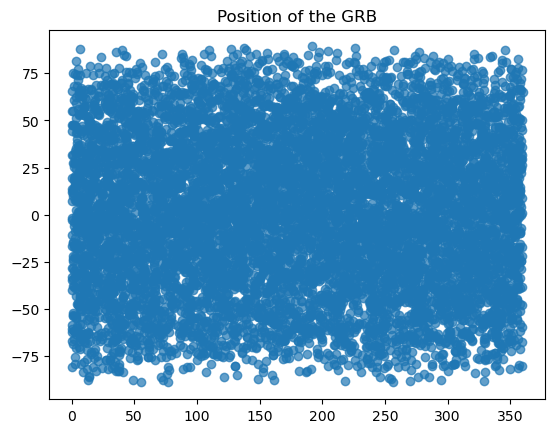

In [4]:
ra = np.array(data[3,:], dtype = float)
decl = np.array(data[4,:], dtype = float)

plt.scatter(ra, decl, alpha = 0.7)
plt.title("Position of the GRB")
plt.show()

In [5]:
T90 = np.array(data[6,:], dtype = float)
z = np.array(data[11,:], dtype = float)
flux = np.array(data[9,:], dtype = float)
T100 = np.array(data[12,:], dtype = float)

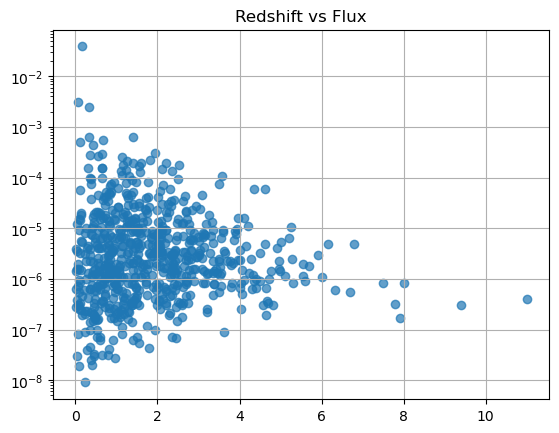

In [6]:
mask_zf = (z != -999) & (flux != -999)

plt.scatter(z[mask_zf], flux[mask_zf], alpha = 0.7)
plt.yscale('log')
plt.grid("True")
plt.title("Redshift vs Flux")
plt.show()

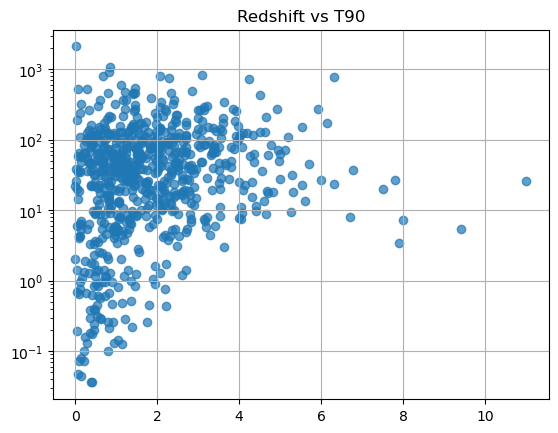

In [7]:
mask_zT = (z != -999) & (T90 != -999)

plt.scatter(z[mask_zT], T90[mask_zT], alpha = 0.7)
plt.yscale('log')
plt.grid("True")
plt.title("Redshift vs T90")
plt.show()

In [9]:
X = np.column_stack([z[mask_zT], T90[mask_zT]])
print(X.shape)

(707, 2)


C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


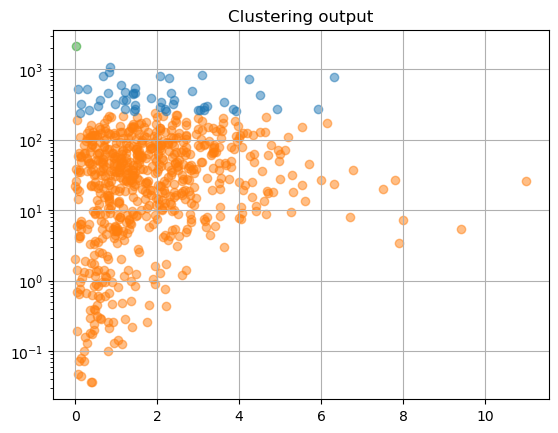

In [10]:
clf = KMeans(n_clusters=3,n_init='auto') #Try 2 clusters to start with
clf.fit(X)
centers = clf.cluster_centers_ #location of the clusters
labels = clf.predict(X) #labels for each of the points

# plot the data color-coded by cluster id
colors = ['C1', 'C0', 'C2']
for ii in range(3):
    plt.scatter(X[labels==ii,0], X[labels==ii,1], 
                color=colors[ii],alpha=0.5)

# To get some information on these try:
# KMeans?
# help(clf)
plt.yscale('log')
plt.grid(True)
plt.title('Clustering output');

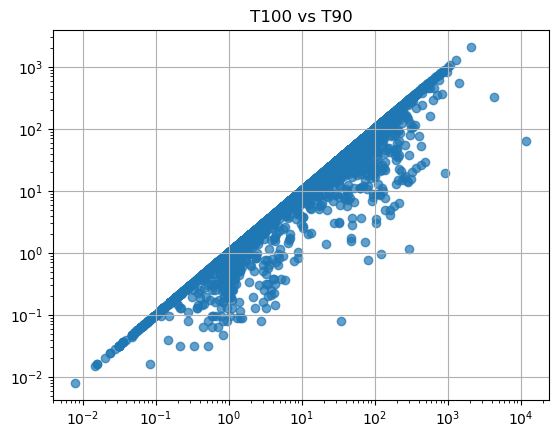

In [19]:
mask_tt = (T90 != -999) & (T100 != -999)

plt.scatter(T100[mask_tt], T90[mask_tt], alpha = 0.7)
plt.yscale('log')
plt.xscale('log')
plt.grid("True")
plt.title("T100 vs T90")
plt.show()

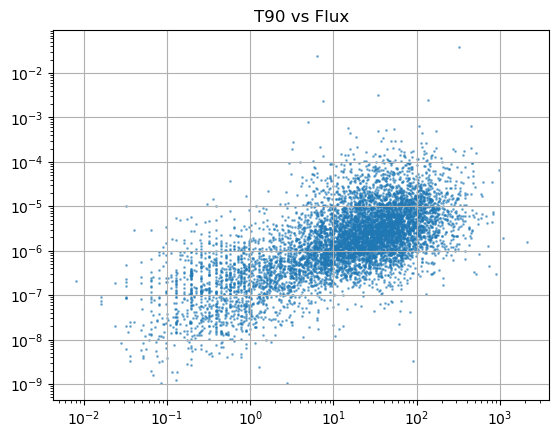

In [35]:
mask_tf = (T90 != -999) & (flux != -999)

plt.scatter(T90[mask_tf], flux[mask_tf], alpha = 0.5, s = 1)
plt.yscale('log')
plt.xscale('log')
plt.grid("True")
plt.title("T90 vs Flux")
plt.show()

In [26]:
X_tf = np.column_stack([T90[mask_tf], flux[mask_tf]])
print(X.shape)
print(np.sum(mask_tf))

(707, 2)
7808


### Histogramming

C:\Users\nicco\AppData\Local\Temp\ipykernel_22220\3293037676.py:2: RuntimeWarning: divide by zero encountered in log10
  lflux = np.log10(flux[flux!=-999])


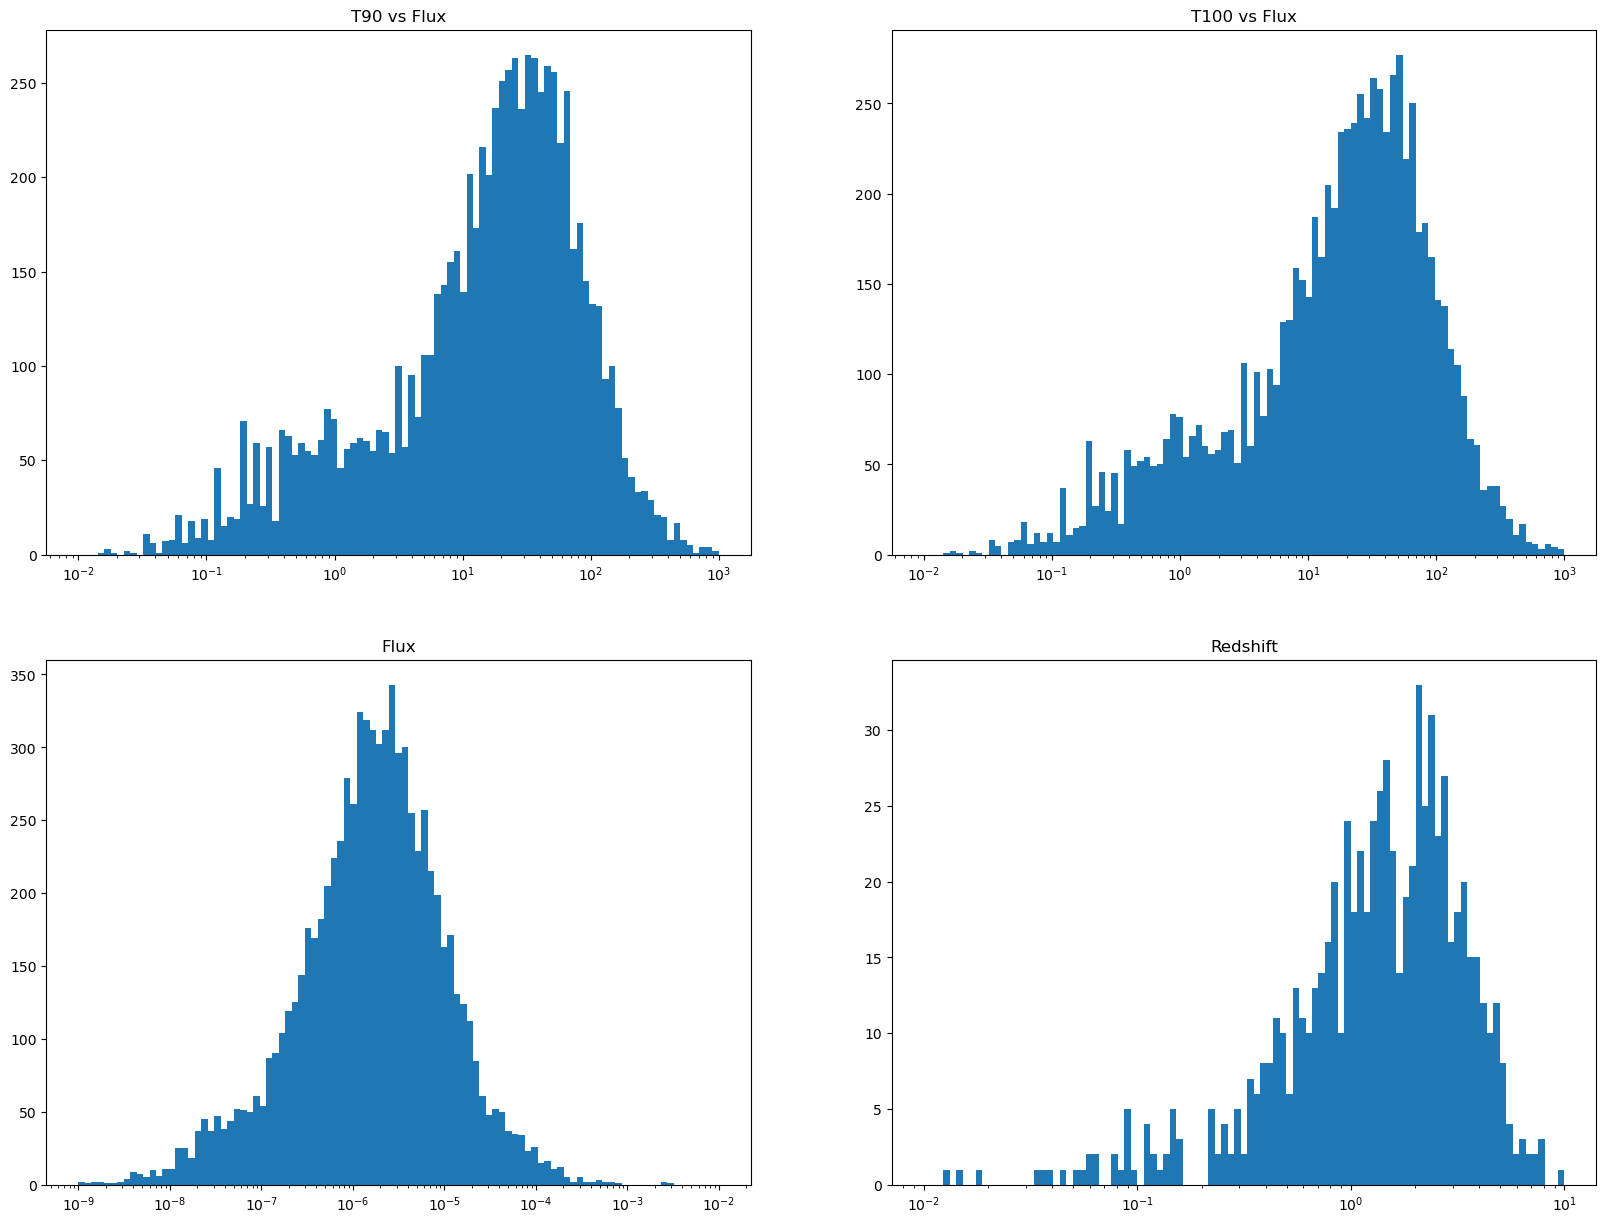

In [52]:
lT90 = np.log10(T90[T90!=-999])
lflux = np.log10(flux[flux!=-999])
lT100 = np.log10(T100[T100!=-999])
lz = np.log10(z[z!=-999])

binsT90 = np.append(np.sort(lT90)[::30], np.max(lT90))
binsT100 = np.append(np.sort(lT100)[::30], np.max(lT100))
binsflux = np.append(np.sort(lflux)[::30], np.max(lflux))
binsz = np.append(np.sort(lz)[::30], np.max(lz))

figure, axes = plt.subplots(2,2, figsize=(20,15))

axes[0,0].hist(T90[T90!=-999], bins = np.logspace(-2,3, 100))  
axes[0,0].set_xscale('log') 
axes[0,0].set_title("T90 vs Flux")

axes[0,1].hist(T100[T100!=-999], bins = np.logspace(-2,3, 100))
axes[0,1].set_xscale('log')
axes[0,1].set_title("T100 vs Flux")

axes[1,0].hist(flux[flux!=-999], bins = np.logspace(-9, -2, 100))
axes[1,0].set_xscale('log')
axes[1,0].set_title("Flux")

axes[1,1].hist(z[z!=-999], bins = np.logspace(-2,1, 100))
axes[1,1].set_xscale('log')
axes[1,1].set_title("Redshift")
plt.show()

C:\Users\nicco\AppData\Local\Temp\ipykernel_22220\3155260285.py:2: RuntimeWarning: divide by zero encountered in log10
  lflux = np.log10(flux[flux!=-999])


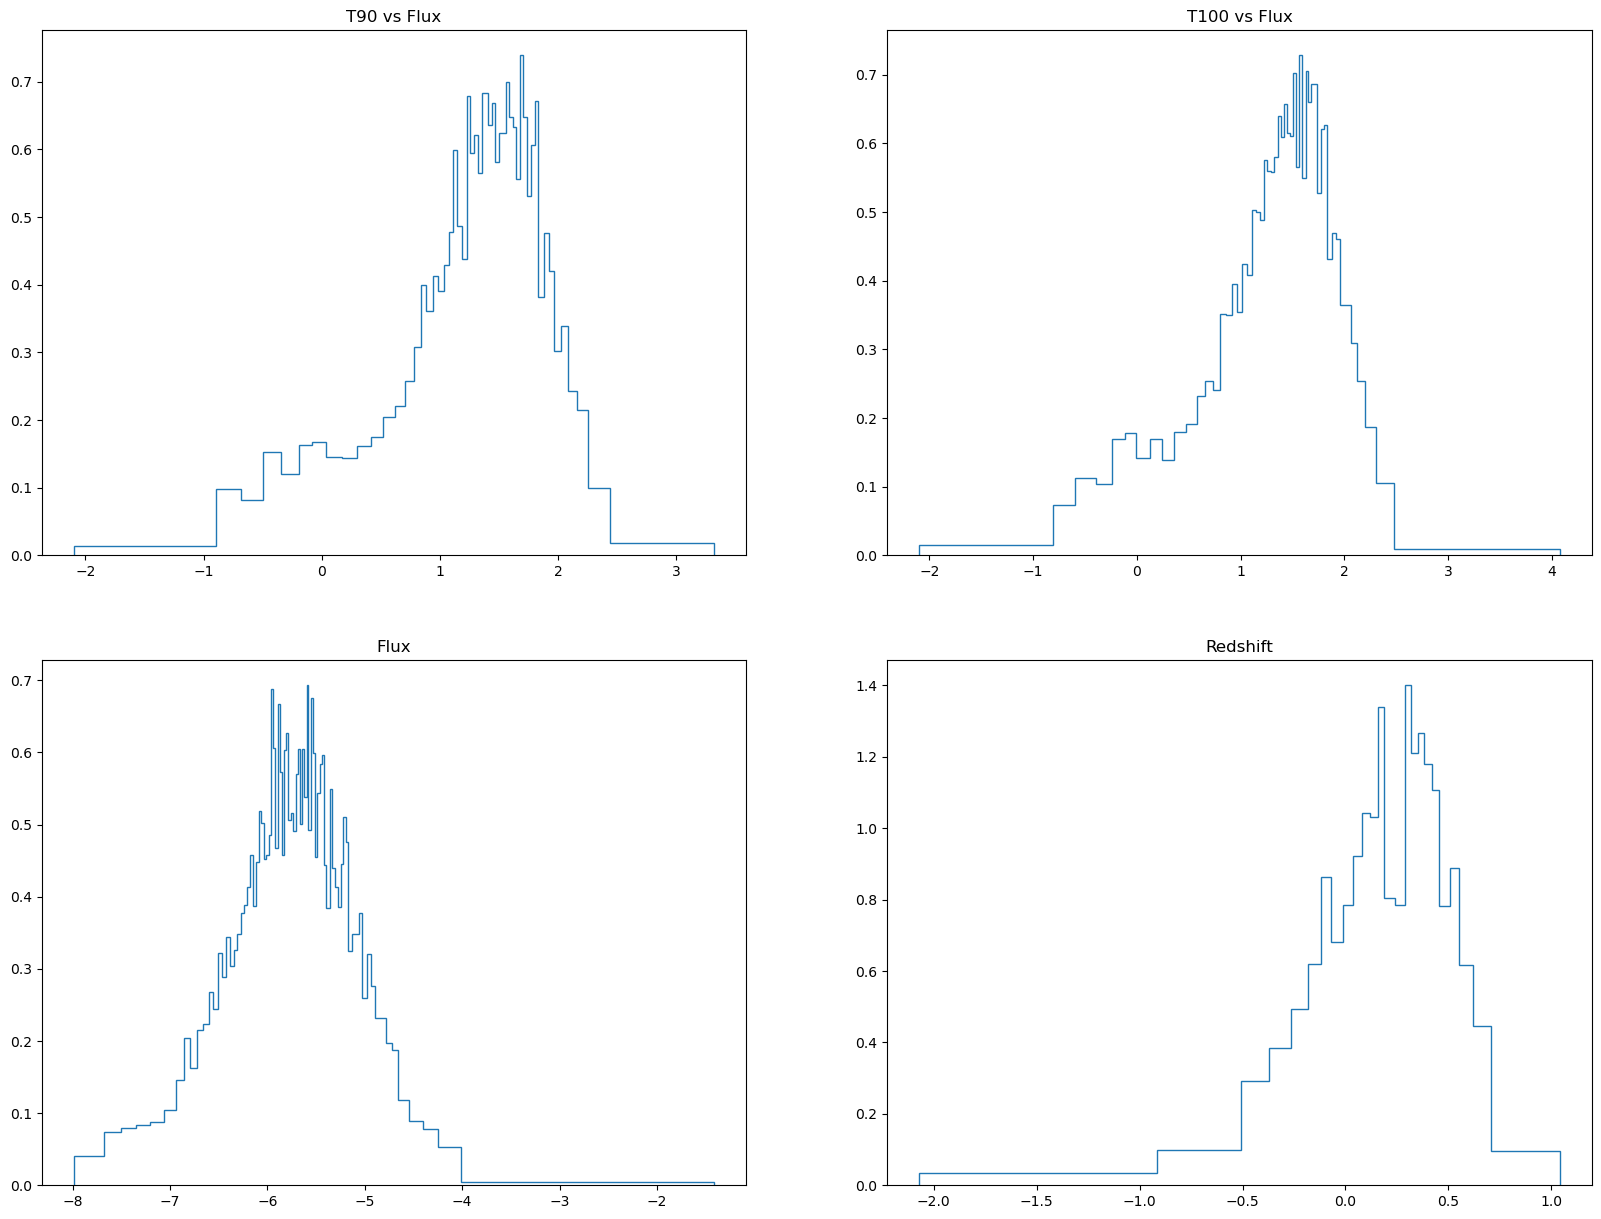

In [54]:
lT90 = np.log10(T90[T90!=-999])
lflux = np.log10(flux[flux!=-999])
lT100 = np.log10(T100[T100!=-999])
lz = np.log10(z[z!=-999])

binsT90 = np.append(np.sort(lT90)[::150], np.max(lT90))
binsT100 = np.append(np.sort(lT100)[::150], np.max(lT100))
binsflux = np.append(np.sort(lflux)[::100], np.max(lflux))
binsz = np.append(np.sort(lz)[::30], np.max(lz))

figure, axes = plt.subplots(2,2, figsize=(20,15))

axes[0,0].hist(lT90, density = True, bins = binsT90, histtype="step")   
axes[0,0].set_title("T90 vs Flux")

axes[0,1].hist(lT100, density = True, bins = binsT100, histtype="step")
axes[0,1].set_title("T100 vs Flux")

axes[1,0].hist(lflux, density = True, bins = binsflux, histtype="step")
axes[1,0].set_title("Flux")

axes[1,1].hist(lz, density = True, bins = binsz, histtype="step")
axes[1,1].set_title("Redshift")
plt.show()

It seems that Only T90 and T100 disciminate between two different populations

### Clustering

Text(0.5, 1.0, 'T90 vs Flux')

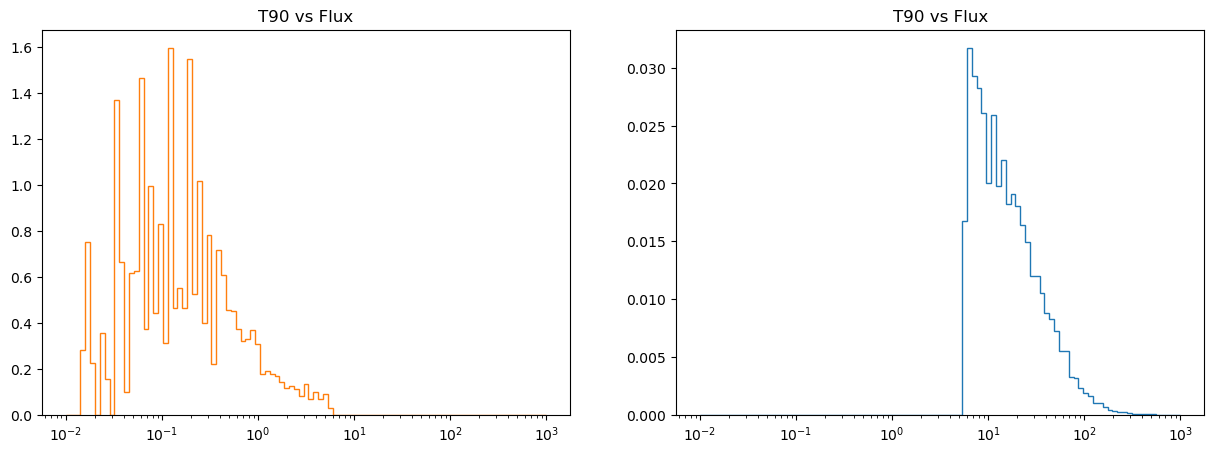

In [ ]:
clT90 = KMeans(n_clusters=2, n_init='auto') #Try 2 clusters to start with
clT90.fit(lT90.reshape(-1,1))
centers = clT90.cluster_centers_ #location of the clusters
centers = 10**np.squeeze(centers)
labels = clT90.predict(lT90.reshape(-1,1)) #labels for each of the points

figure, axes = plt.subplots(1,2, figsize=(15,5))

axes[0].hist(10**lT90[labels == 0], bins = np.logspace(-2,3, 100), histtype="step", density = True, color = 'C1')  
axes[0].set_xscale('log') 
axes[0].set_title("T90 vs Flux")

axes[1].hist(10**lT90[labels==1], bins = np.logspace(-2,3, 100), histtype="step", density = True, color = 'C0')
axes[1].set_xscale('log')
axes[1].set_title("T90 vs Flux")


In [62]:
skT90 = lT90[:,np.newaxis]
kde = KernelDensity(kernel='gaussian', bandwidth=0.2).fit(skT90)
edge = 10**( np.mean( [max(skT90[labels==0]), min(skT90[labels==1]) ]))

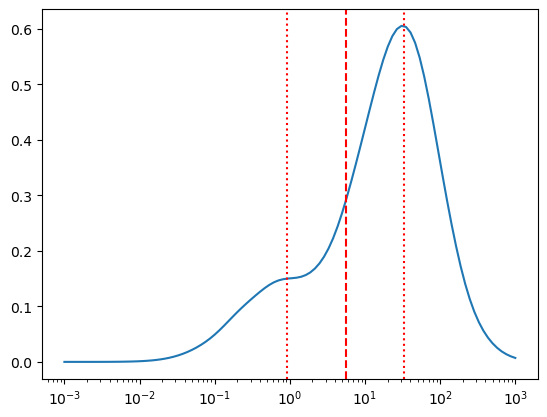

In [63]:
xgrid=np.logspace(-3,3,100)
ygrid = np.exp(kde.score_samples(np.log10(xgrid)[:,np.newaxis]))
plt.plot(xgrid,ygrid)
plt.semilogx()
for v in centers:
    plt.axvline(v, c='red',ls='dotted')
plt.axvline(edge,c='red',ls='dashed');